In [128]:
from requests import Session
from requests.exceptions import ConnectionError, Timeout, TooManyRedirects
import json
import pandas as pd

url = 'https://pro-api.coinmarketcap.com/v1/cryptocurrency/listings/latest'
#Original Sandbox Environment: 'https://sandbox-api.coinmarketcap.com/v1/cryptocurrency/listings/latest'
parameters = {
    'start':'1',
    'limit':'15',
    'convert':'USD'
}
headers = {
    'Accepts': 'application/json',
    'X-CMC_PRO_API_KEY': 'e1d3dfe126e54f16ad62cd1bee0cb2bc',
}

session = Session()
session.headers.update(headers)

try:
    response = session.get(url, params=parameters)
    response.raise_for_status()
    data = response.json()
    #print(data)
except (ConnectionError, Timeout, TooManyRedirects) as e:
    print(e)

In [129]:
type(data)

dict

In [130]:
import pandas as pd

#This allows you to see all the columns, not just like 15
pd.set_option('display.max_columns', None)
#pd.set_option('display.max_rows', None)

In [131]:
#This normalizes the data and makes it all pretty in a dataframe

df = pd.json_normalize(data['data'])
df['timestamp'] = pd.to_datetime('now')
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,20110575.00000,20110575.00000,21000000.00000,2010-07-13T00:00:00.000Z,12778,1,2026-11-11T06:02:03.021Z,None,NaN,NaN,NaN,1484565081650.27002,"[mineable, pow, sha-256, store-of-value, state...",73820.12109,28979425521.21063,28917183762.38047,62241758.83016,15.98833,0.30171,-1.12183,-5.01192,-11.98165,-4.37284,15.71959,1484565081650.26758,60.42080,1550222542849.00000,None,2026-11-11T06:02:03.021Z,NaN,NaN,NaN,NaN,NaN,2026-11-11 11:32:18.228692
1,1027,Ethereum,ETH,ethereum,True,122209757.95344,122209757.95344,NaN,2015-08-07T00:00:00.000Z,14313,2,2026-11-11T06:02:03.230Z,None,NaN,NaN,NaN,252740289808.66000,"[pos, smart-contracts, ethereum-ecosystem, coi...",2068.08600,14000770641.39026,13690074819.60556,310695821.78470,17.66266,0.35774,-2.47129,-9.75309,-19.24216,-17.63630,9.21604,252740289808.66458,10.28530,252740289808.66000,None,2026-11-11T06:02:03.230Z,NaN,NaN,NaN,NaN,NaN,2026-11-11 11:32:18.228692
2,825,Tether USDt,USDT,tether,True,175956792475.50842,184272871874.26431,NaN,2015-02-25T00:00:00.000Z,206843,3,2026-11-11T06:02:03.135Z,None,NaN,NaN,NaN,184023091226.89001,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.99864,61786798264.15916,60345721707.41685,1441076556.74221,10.60456,-0.00150,-0.01732,0.01617,-0.01020,-0.10759,-0.02561,175718284218.22827,7.14970,184023091226.89001,None,2026-11-11T06:02:03.135Z,1027.00000,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-11-11 11:32:18.228692
3,1839,BNB,BNB,bnb,False,131510837.07000,131510837.07000,131510837.07000,2017-07-25T00:00:00.000Z,3525,4,2026-11-11T06:02:03.135Z,None,NaN,NaN,NaN,89596333019.11000,"[marketplace, centralized-exchange, payments, ...",681.28479,1401391483.34501,1383724071.32642,17667412.01860,-1.93461,0.13906,-1.30991,-2.33946,-9.47602,-7.04289,11.10620,89596333019.11429,3.64550,89596333019.11000,None,2026-11-11T06:02:03.135Z,NaN,NaN,NaN,NaN,NaN,2026-11-11 11:32:18.228692
4,3408,USDC,USDC,usd-coin,False,69971335387.93594,69971335387.93594,NaN,2018-10-08T00:00:00.000Z,47436,5,2026-11-11T06:02:03.230Z,None,NaN,60901219650.23000,60880190508.16181,69947174342.21001,"[medium-of-exchange, stablecoin, asset-backed-...",0.99965,12589204077.89276,10226963106.42491,2362240971.46791,19.56287,-0.00265,-0.02304,-0.01408,-0.01640,-0.01250,-0.00915,69947174342.21265,2.84650,69947174342.21001,None,2026-11-11T06:02:03.230Z,24091.00000,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-11-11 11:32:18.228692
5,52,XRP,XRP,xrp,False,63516606953.00000,99985583260.00000,100000000000.00000,2013-08-04T00:00:00.000Z,1895,6,2026-11-11T06:02:03.111Z,None,NaN,NaN,NaN,106113083634.09000,"[medium-of-exchange, enterprise-solutions, xrp...",1.06128,2692342327.94273,2690638339.78028,1703988.16245,3.73570,0.77252,-3.34828,-16.79117,-24.83507,-22.18828,4.77554,67409148459.24438,2.74320,106128383887.25999,None,2026-11-11T06:02:03.111Z,NaN,NaN,NaN,NaN,NaN,2026-11-11 11:32:18.228692
6,5426,Solana,SOL,solana,True,591408495.49621,637371997.95186,NaN,2020-04-10T00:00:00.000Z,1189,7,2026-11-11T06:02:03.125Z,None,NaN,525236893.30000,43746469534.36243,53086093239.32000,"[pos, platform, solana-ecosystem, cms-holdings...",83.28903,3073438753.66748,3068490952.01357,4947801.65391,34.44619,0.70472,-3.34538,-10.14110,-26.10

In [132]:
def api_runner():
    global df
    url = 'https://pro-api.coinmarketcap.com/v1/cryptocurrency/listings/latest'
    #Original Sandbox Environment: 'https://sandbox-api.coinmarketcap.com/v1/cryptocurrency/listings/latest'
    parameters = {
        'start':'1',
        'limit':'15',
        'convert':'USD'
    }
    headers = {
        'Accepts': 'application/json',
        'X-CMC_PRO_API_KEY': 'e1d3dfe126e54f16ad62cd1bee0cb2bc',
    }
    
    session = Session()
    session.headers.update(headers)
    
    try:
        response = session.get(url, params=parameters)
        response.raise_for_status()
        data = response.json()
        #print(data)
    except (ConnectionError, Timeout, TooManyRedirects) as e:
        print(e)

    df = pd.json_normalize(data['data'])
    df['timestamp'] = pd.to_datetime('now')
    df

    if not os.path.isfile(r'C:\Users\DELL\OneDrive\Documents\Python Scripts\API.csv'):
        df.to_csv(r'C:\Users\DELL\OneDrive\Documents\Python Scripts\API.csv', header='column_names')
    else:
        df.to_csv(r'C:\Users\DELL\OneDrive\Documents\Python Scripts\API.csv', mode='a', header=False)

In [133]:
import os
from time import time, sleep
for i in range(333):
    api_runner()
    print('API Runner completed')
    sleep(60) #sleep for 60 seconds
exit()

API Runner completed
API Runner completed
API Runner completed
API Runner completed
API Runner completed


KeyboardInterrupt: 

In [134]:
df72 = pd.read_csv(r'C:\Users\DELL\OneDrive\Documents\Python Scripts\API.csv')
df72

,Unnamed: 0,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,0,1,Bitcoin,BTC,bitcoin,False,20109793.00000,20109793.00000,21000000.00000,2010-07-13T00:00:00.000Z,12776,1,2026-11-09T07:31:33.025Z,NaN,NaN,NaN,NaN,1485946182182.93994,"['mineable', 'pow', 'sha-256', 'store-of-value...",73891.66970,22133326460.02947,22085385150.13159,47941309.89788,149.92546,-0.46534,-2.43643,-5.22390,-10.50561,-5.28562,15.63264,1485946182182.94189,60.25670,1551725063795.62012,NaN,2026-11-09T07:31:33.025Z,NaN,NaN,NaN,NaN,NaN,2026-11-09 13:01:49.694825
1,1,1027,Ethereum,ETH,ethereum,True,122203846.69715,122203846.69715,NaN,2015-08-07T00:00:00.000Z,14299,2,2026-11-09T07:31:33.170Z,NaN,NaN,NaN,NaN,255197939485.23999,"['pos', 'smart-contracts', 'ethereum-ecosystem...",2088.29711,11996395795.42399,11765163322.32222,231232473.10177,214.88700,-1.38859,-6.45212,-8.36193,-16.16630,-15.37148,11.58518,255197939485.24045,10.34850,255197939485.23999,NaN,2026-11-09T07:31:33.170Z,NaN,NaN,NaN,NaN,NaN,2026-11-09 13:01:49.694825
2,2,825,Tether USDt,USDT,tether,True,177044537567.82022,184298182379.34583,NaN,2015-02-25T00:00:00.000Z,206699,3,2026-11-09T07:31:33.102Z,NaN,NaN,NaN,NaN,184059583561.57001,"['stablecoin', 'asset-backed-stablecoin', 'usd...",0.99871,49513403371.44550,48209001793.91460,1304401577.53093,109.13473,-0.00834,0.01672,0.01009,-0.03882,-0.09277,-0.03010,176815329570.15253,7.17000,184059583561.57001,NaN,2026-11-09T07:31:33.102Z,1027.00000,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-11-09 13:01:49.694825
3,3,1839,BNB,BNB,bnb,False,131510946.00000,131510946.00000,131510946.00000,2017-07-25T00:00:00.000Z,3525,4,2026-11-09T07:31:33.102Z,NaN,NaN,NaN,NaN,88803012100.31000,"['marketplace', 'centralized-exchange', 'payme...",675.25187,1442068217.34258,1409386075.93563,32682141.40696,48.69373,-0.88555,-3.25813,-4.50307,-9.68994,-5.82254,12.74723,88803012100.31462,3.60110,88803012100.31000,NaN,2026-11-09T07:31:33.102Z,NaN,NaN,NaN,NaN,NaN,2026-11-09 13:01:49.694825
4,4,3408,USDC,USDC,usd-coin,False,70319515702.02744,70319515702.02744,NaN,2018-10-08T00:00:00.000Z,47395,5,2026-11-09T07:31:33.025Z,NaN,NaN,60901219650.23000,60885334742.61913,70301174213.69000,"['medium-of-exchange', 'stablecoin', 'asset-ba...",0.99974,8635886061.33160,6905455647.80031,1730430413.53128,114.68624,-0.00421,-0.00248,0.01329,-0.01144,-0.01686,-0.01227,70301174213.68643,2.85080,70301174213.69000,NaN,2026-11-09T07:31:33.025Z,24091.00000,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-11-09 13:01:49.694825
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
265,10,328,Monero,XMR,monero,True,18829460.01783,18829460.01783,NaN,2014-05-21T00:00:00.000Z,383,11,2026-11-11T06:06:18.030Z,NaN,NaN,NaN,NaN,10725435581.09000,"['mineable', 'pow', 'medium-of-exchange', 'pri...",569.60930,159361014.81490,159361014.81490,0.00000,10.37015,0.06967,0.96184,-10.05299,7.19690,5.35862,44.50157,10725435581.08755,0.43650,10725435581.09000,NaN,2026-11-11T06:06:18.030Z,NaN,NaN,NaN,NaN,NaN,2026-11-11 11:36:30.176968
266,11,74,Dogecoin,DOGE,dogecoin,True,156700272860.16907,156700272860.16907,NaN,2013-12-15T00:00:00.000Z,1545,12,2026-11-11T06:06:18.194Z,NaN,NaN,NaN,NaN,10689822740.17000,"['

In [135]:
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,20110575.00000,20110575.00000,21000000.00000,2010-07-13T00:00:00.000Z,12778,1,2026-11-11T06:06:18.030Z,None,NaN,NaN,NaN,1483328782040.27002,"[mineable, pow, sha-256, store-of-value, state...",73758.64599,29141608080.15126,29079317960.53692,62290119.61434,17.59538,0.03600,-1.19381,-5.14716,-11.99586,-4.45693,15.68929,1483328782040.27466,60.37270,1548931565748.15991,None,2026-11-11T06:06:18.030Z,NaN,NaN,NaN,NaN,NaN,2026-11-11 11:36:30.176968
1,1027,Ethereum,ETH,ethereum,True,122209757.95344,122209757.95344,NaN,2015-08-07T00:00:00.000Z,14313,2,2026-11-11T06:06:18.257Z,None,NaN,NaN,NaN,252418548758.89001,"[pos, smart-contracts, ethereum-ecosystem, coi...",2065.45331,14170620778.60491,13876942082.26334,293678696.34158,19.15044,0.04871,-2.57808,-9.84333,-19.26258,-17.74568,9.21262,252418548758.89270,10.27780,252418548758.89001,None,2026-11-11T06:06:18.257Z,NaN,NaN,NaN,NaN,NaN,2026-11-11 11:36:30.176968
2,825,Tether USDt,USDT,tether,True,175956792475.50842,184272871874.26431,NaN,2015-02-25T00:00:00.000Z,206843,3,2026-11-11T06:06:18.139Z,None,NaN,NaN,NaN,184014434421.64999,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.99860,61958664091.42699,60516871400.49239,1441792690.93446,11.84922,-0.01017,-0.01582,0.00605,-0.02665,-0.11952,-0.03766,175710018087.30972,7.15480,184014434421.64999,None,2026-11-11T06:06:18.139Z,1027.00000,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-11-11 11:36:30.176968
3,1839,BNB,BNB,bnb,False,131510837.07000,131510837.07000,131510837.07000,2017-07-25T00:00:00.000Z,3525,4,2026-11-11T06:06:18.139Z,None,NaN,NaN,NaN,89545455969.97000,"[marketplace, centralized-exchange, payments, ...",680.89792,1402979593.13190,1385356425.91555,17623167.21635,-1.52430,0.02728,-1.36726,-2.41358,-9.49134,-7.06820,11.15253,89545455969.97354,3.64620,89545455969.97000,None,2026-11-11T06:06:18.139Z,NaN,NaN,NaN,NaN,NaN,2026-11-11 11:36:30.176968
4,3408,USDC,USDC,usd-coin,False,69971335387.93594,69971335387.93594,NaN,2018-10-08T00:00:00.000Z,47436,5,2026-11-11T06:06:18.257Z,None,NaN,60901219650.23000,60874148145.94569,69940232081.36000,"[medium-of-exchange, stablecoin, asset-backed-...",0.99956,12670586093.99158,10322578198.28056,2348007895.71107,17.56321,-0.02012,-0.02657,-0.02972,-0.03644,-0.03302,-0.02689,69940232081.35829,2.84780,69940232081.36000,None,2026-11-11T06:06:18.257Z,24091.00000,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-11-11 11:36:30.176968
5,52,XRP,XRP,xrp,False,63516606953.00000,99985583260.00000,100000000000.00000,2013-08-04T00:00:00.000Z,1895,6,2026-11-11T06:06:18.109Z,None,NaN,NaN,NaN,106078790124.84000,"[medium-of-exchange, enterprise-solutions, xrp...",1.06094,2689440731.25926,2687737067.47569,1703663.78357,4.23137,0.61493,-3.32506,-16.80923,-24.79371,-22.18777,4.78221,67387363245.04181,2.74380,106094085433.28999,None,2026-11-11T06:06:18.109Z,NaN,NaN,NaN,NaN,NaN,2026-11-11 11:36:30.176968
6,5426,Solana,SOL,solana,True,591408495.49621,637371997.95186,NaN,2020-04-10T00:00:00.000Z,1189,7,2026-11-11T06:06:18.122Z,None,NaN,525236893.30000,43685336978.09990,53011909228.22000,"[pos, platform, solana-ecosystem, cms-holdings...",83.17264,3075538686.18067,3070586148.83794,4952537.34273,34.86933,0.48418,-3.40201,-10.33131,-26.15

In [136]:
pd.set_option('display.float_format', lambda x: '%.5f' % x)

In [137]:
df

,id,name,symbol,slug,infinite_supply,circulating_supply,total_supply,max_supply,date_added,num_market_pairs,cmc_rank,last_updated,tvl_ratio,platform,self_reported_circulating_supply,self_reported_market_cap,minted_market_cap,tags,quote.USD.price,quote.USD.volume_24h,quote.USD.cex_volume_24h,quote.USD.dex_volume_24h,quote.USD.volume_change_24h,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d,quote.USD.market_cap,quote.USD.market_cap_dominance,quote.USD.fully_diluted_market_cap,quote.USD.tvl,quote.USD.last_updated,platform.id,platform.slug,platform.name,platform.symbol,platform.token_address,timestamp
0,1,Bitcoin,BTC,bitcoin,False,20110575.00000,20110575.00000,21000000.00000,2010-07-13T00:00:00.000Z,12778,1,2026-11-11T06:06:18.030Z,None,NaN,NaN,NaN,1483328782040.27002,"[mineable, pow, sha-256, store-of-value, state...",73758.64599,29141608080.15126,29079317960.53692,62290119.61434,17.59538,0.03600,-1.19381,-5.14716,-11.99586,-4.45693,15.68929,1483328782040.27466,60.37270,1548931565748.15991,None,2026-11-11T06:06:18.030Z,NaN,NaN,NaN,NaN,NaN,2026-11-11 11:36:30.176968
1,1027,Ethereum,ETH,ethereum,True,122209757.95344,122209757.95344,NaN,2015-08-07T00:00:00.000Z,14313,2,2026-11-11T06:06:18.257Z,None,NaN,NaN,NaN,252418548758.89001,"[pos, smart-contracts, ethereum-ecosystem, coi...",2065.45331,14170620778.60491,13876942082.26334,293678696.34158,19.15044,0.04871,-2.57808,-9.84333,-19.26258,-17.74568,9.21262,252418548758.89270,10.27780,252418548758.89001,None,2026-11-11T06:06:18.257Z,NaN,NaN,NaN,NaN,NaN,2026-11-11 11:36:30.176968
2,825,Tether USDt,USDT,tether,True,175956792475.50842,184272871874.26431,NaN,2015-02-25T00:00:00.000Z,206843,3,2026-11-11T06:06:18.139Z,None,NaN,NaN,NaN,184014434421.64999,"[stablecoin, asset-backed-stablecoin, usd-stab...",0.99860,61958664091.42699,60516871400.49239,1441792690.93446,11.84922,-0.01017,-0.01582,0.00605,-0.02665,-0.11952,-0.03766,175710018087.30972,7.15480,184014434421.64999,None,2026-11-11T06:06:18.139Z,1027.00000,ethereum,Ethereum,ETH,0xdac17f958d2ee523a2206206994597c13d831ec7,2026-11-11 11:36:30.176968
3,1839,BNB,BNB,bnb,False,131510837.07000,131510837.07000,131510837.07000,2017-07-25T00:00:00.000Z,3525,4,2026-11-11T06:06:18.139Z,None,NaN,NaN,NaN,89545455969.97000,"[marketplace, centralized-exchange, payments, ...",680.89792,1402979593.13190,1385356425.91555,17623167.21635,-1.52430,0.02728,-1.36726,-2.41358,-9.49134,-7.06820,11.15253,89545455969.97354,3.64620,89545455969.97000,None,2026-11-11T06:06:18.139Z,NaN,NaN,NaN,NaN,NaN,2026-11-11 11:36:30.176968
4,3408,USDC,USDC,usd-coin,False,69971335387.93594,69971335387.93594,NaN,2018-10-08T00:00:00.000Z,47436,5,2026-11-11T06:06:18.257Z,None,NaN,60901219650.23000,60874148145.94569,69940232081.36000,"[medium-of-exchange, stablecoin, asset-backed-...",0.99956,12670586093.99158,10322578198.28056,2348007895.71107,17.56321,-0.02012,-0.02657,-0.02972,-0.03644,-0.03302,-0.02689,69940232081.35829,2.84780,69940232081.36000,None,2026-11-11T06:06:18.257Z,24091.00000,zksync,zkSync Era,ZK,0x1d17CBcF0D6D143135aE902365D2E5e2A16538D4,2026-11-11 11:36:30.176968
5,52,XRP,XRP,xrp,False,63516606953.00000,99985583260.00000,100000000000.00000,2013-08-04T00:00:00.000Z,1895,6,2026-11-11T06:06:18.109Z,None,NaN,NaN,NaN,106078790124.84000,"[medium-of-exchange, enterprise-solutions, xrp...",1.06094,2689440731.25926,2687737067.47569,1703663.78357,4.23137,0.61493,-3.32506,-16.80923,-24.79371,-22.18777,4.78221,67387363245.04181,2.74380,106094085433.28999,None,2026-11-11T06:06:18.109Z,NaN,NaN,NaN,NaN,NaN,2026-11-11 11:36:30.176968
6,5426,Solana,SOL,solana,True,591408495.49621,637371997.95186,NaN,2020-04-10T00:00:00.000Z,1189,7,2026-11-11T06:06:18.122Z,None,NaN,525236893.30000,43685336978.09990,53011909228.22000,"[pos, platform, solana-ecosystem, cms-holdings...",83.17264,3075538686.18067,3070586148.83794,4952537.34273,34.86933,0.48418,-3.40201,-10.33131,-26.15

In [138]:
df3 = df.groupby('name', sort=False)[['quote.USD.percent_change_1h', 'quote.USD.percent_change_24h', 'quote.USD.percent_change_7d', 'quote.USD.percent_change_30d', 'quote.USD.percent_change_60d', 'quote.USD.percent_change_90d']].mean()
df3

,quote.USD.percent_change_1h,quote.USD.percent_change_24h,quote.USD.percent_change_7d,quote.USD.percent_change_30d,quote.USD.percent_change_60d,quote.USD.percent_change_90d
name,,,,,,
Bitcoin,0.03600,-1.19381,-5.14716,-11.99586,-4.45693,15.68929
Ethereum,0.04871,-2.57808,-9.84333,-19.26258,-17.74568,9.21262
Tether USDt,-0.01017,-0.01582,0.00605,-0.02665,-0.11952,-0.03766
BNB,0.02728,-1.36726,-2.41358,-9.49134,-7.06820,11.15253
USDC,-0.02012,-0.02657,-0.02972,-0.03644,-0.03302,-0.02689
XRP,0.61493,-3.32506,-16.80923,-24.79371,-22.18777,4.78221
Solana,0.48418,-3.40201,-10.33131,-26.15376,-18.14245,8.83834
TRON,-0.02643,-0.03105,-1.21613,-4.41010,-7.71544,-5.98275
Hyperliquid,0.11223,-3.68228,-14.69502,-17.57519,-8.23260,26.13202


In [139]:
df4 = df3.stack()
df4

name                                 
Bitcoin  quote.USD.percent_change_1h      0.03600
         quote.USD.percent_change_24h    -1.19381
         quote.USD.percent_change_7d     -5.14716
         quote.USD.percent_change_30d   -11.99586
         quote.USD.percent_change_60d    -4.45693
                                           ...   
Cardano  quote.USD.percent_change_24h    -1.82662
         quote.USD.percent_change_7d     -7.79109
         quote.USD.percent_change_30d   -30.82753
         quote.USD.percent_change_60d   -15.63844
         quote.USD.percent_change_90d    -4.91189
Length: 90, dtype: float64

In [140]:
type(df3)

pandas.DataFrame

In [141]:
type(df4)

pandas.Series

In [142]:
df5 = df4.to_frame(name='values')
df5

values
name                                          
Bitcoin quote.USD.percent_change_1h    0.03600
        quote.USD.percent_change_24h  -1.19381
        quote.USD.percent_change_7d   -5.14716
        quote.USD.percent_change_30d -11.99586
        quote.USD.percent_change_60d  -4.45693
...                                        ...
Cardano quote.USD.percent_change_24h  -1.82662
        quote.USD.percent_change_7d   -7.79109
        quote.USD.percent_change_30d -30.82753
        quote.USD.percent_change_60d -15.63844
        quote.USD.percent_change_90d  -4.91189

[90 rows x 1 columns]

In [143]:
df5.count()

values    90
dtype: int64

In [144]:
index = pd.Index(range(90))
df6 = df5.reset_index()
df6

,name,level_1,values
0,Bitcoin,quote.USD.percent_change_1h,0.03600
1,Bitcoin,quote.USD.percent_change_24h,-1.19381
2,Bitcoin,quote.USD.percent_change_7d,-5.14716
3,Bitcoin,quote.USD.percent_change_30d,-11.99586
4,Bitcoin,quote.USD.percent_change_60d,-4.45693
...,...,...,...
85,Cardano,quote.USD.percent_change_24h,-1.82662
86,Cardano,quote.USD.percent_change_7d,-7.79109
87,Cardano,quote.USD.percent_change_30d,-30.82753
88,Cardano,quote.USD.percent_change_60d,-15.63844


In [145]:
df7 = df6.rename(columns={'level_1': 'percent_change'})
df7

,name,percent_change,values
0,Bitcoin,quote.USD.percent_change_1h,0.03600
1,Bitcoin,quote.USD.percent_change_24h,-1.19381
2,Bitcoin,quote.USD.percent_change_7d,-5.14716
3,Bitcoin,quote.USD.percent_change_30d,-11.99586
4,Bitcoin,quote.USD.percent_change_60d,-4.45693
...,...,...,...
85,Cardano,quote.USD.percent_change_24h,-1.82662
86,Cardano,quote.USD.percent_change_7d,-7.79109
87,Cardano,quote.USD.percent_change_30d,-30.82753
88,Cardano,quote.USD.percent_change_60d,-15.63844


In [146]:
df7['percent_change'] = df7['percent_change'].replace(['quote.USD.percent_change_24h', 'quote.USD.percent_change_7d', 'quote.USD.percent_change_30d', 'quote.USD.percent_change_60d', 'quote.USD.percent_change_90d'],['24h', '7d', '30d', '60d', '90d'])
df7

,name,percent_change,values
0,Bitcoin,quote.USD.percent_change_1h,0.03600
1,Bitcoin,24h,-1.19381
2,Bitcoin,7d,-5.14716
3,Bitcoin,30d,-11.99586
4,Bitcoin,60d,-4.45693
...,...,...,...
85,Cardano,24h,-1.82662
86,Cardano,7d,-7.79109
87,Cardano,30d,-30.82753
88,Cardano,60d,-15.63844


In [147]:
import seaborn as sns
import matplotlib.pyplot as plt

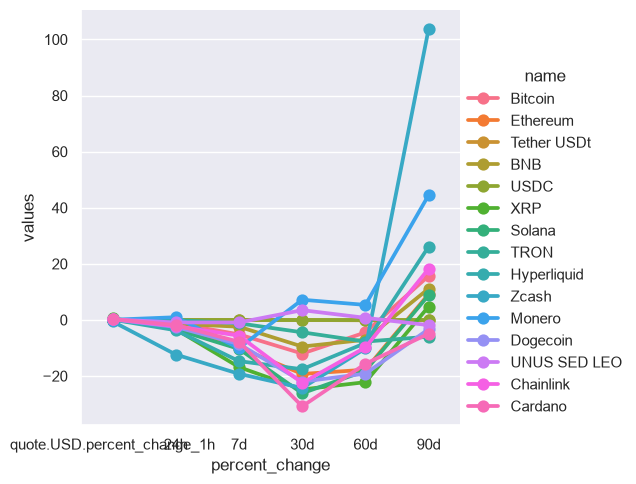

In [148]:
sns.catplot(x='percent_change', y='values', hue='name', data=df7, kind='point')

In [149]:
df10 = df[['name', 'quote.USD.price', 'timestamp']]
df10 = df10.query("name == 'Bitcoin'")
df10

,name,quote.USD.price,timestamp
0,Bitcoin,73758.64599,2026-11-11 11:36:30.176968


<Axes: xlabel='timestamp', ylabel='quote.USD.price'>

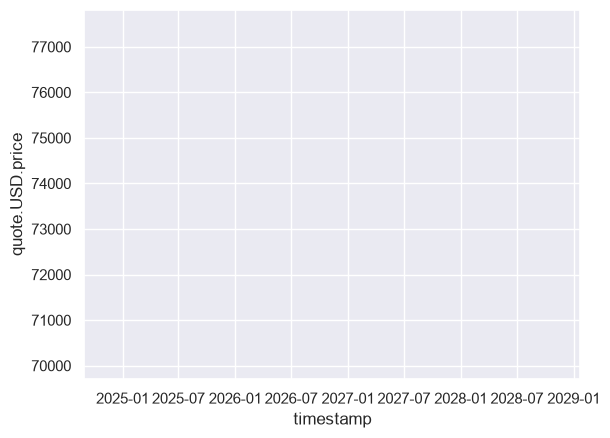

In [150]:
sns.set_theme(style='darkgrid')
sns.lineplot(x='timestamp', y='quote.USD.price', data = df10)